In [2]:
# ==========================================================
# BEGINNER LSTM PROJECT
# Electricity Consumption Prediction
# ==========================================================

# Import required libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [15]:
# ==========================================================
# STEP 1: CREATE DATASET
# ==========================================================

# Simple electricity consumption values
data = np.array([
    100, 110, 120, 130, 140,
    150, 160, 170, 180, 190,
    200, 210, 220, 230, 240,
    250, 260, 270, 280, 290
])

# Display original data
print("Original Data:")
print(data)


Original Data:
[100 110 120 130 140 150 160 170 180 190 200 210 220 230 240 250 260 270
 280 290]


In [4]:

# ==========================================================
# STEP 2: NORMALIZE DATA
# ==========================================================

# Create MinMaxScaler
scaler = MinMaxScaler()

# Convert data into values between 0 and 1
data_scaled = scaler.fit_transform(data.reshape(-1, 1))

# Display normalized data
print("\nNormalized Data:")
print(data_scaled[:5])



Normalized Data:
[[0.        ]
 [0.05263158]
 [0.10526316]
 [0.15789474]
 [0.21052632]]


In [5]:
# ==========================================================
# STEP 3: CREATE SEQUENCES
# ==========================================================

# Use previous 3 values to predict next value
sequence_length = 3

# Create empty lists
X = []
y = []

# Generate sequences
for i in range(len(data_scaled) - sequence_length):

    # Input: previous 3 values
    X.append(data_scaled[i:i + sequence_length])

    # Output: next value
    y.append(data_scaled[i + sequence_length])


# Convert lists into NumPy arrays
X = np.array(X)
y = np.array(y)

# Display shapes
print("\nInput Shape:", X.shape)
print("Output Shape:", y.shape)


Input Shape: (17, 3, 1)
Output Shape: (17, 1)


In [6]:
# ==========================================================
# STEP 4: CREATE LSTM MODEL
# ==========================================================

# Create Sequential model
model = Sequential()

# Add LSTM layer with 50 units
model.add(
    LSTM(
        50,
        activation="tanh",
        input_shape=(sequence_length, 1)
    )
)

# Add Dense output layer
model.add(Dense(1))


c:\Users\arifv\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [7]:
# ==========================================================
# STEP 5: COMPILE MODEL
# ==========================================================

# Configure model training
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display model architecture
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# ==========================================================
# STEP 6: TRAIN MODEL
# ==========================================================

# Train the LSTM model
history = model.fit(
    X,
    y,
    epochs=300,
    batch_size=4,
    verbose=1
)


Epoch 1/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.3943
Epoch 2/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3300 
Epoch 3/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.2747
Epoch 4/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2228 
Epoch 5/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1771
Epoch 6/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.1280
Epoch 7/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0907
Epoch 8/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0564 
Epoch 9/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0335
Epoch 10/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0184 
Epoch 11/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0105 
Epoch 12/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0084
Epoch 13/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0095
Epoch 14/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0096
Epoch 15/300
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0083
Epoch 16/300
5/5 ━

In [9]:
# ==========================================================
# STEP 7: PREDICT NEXT VALUE
# ==========================================================

# Take the last 3 original values
last_values = np.array([270, 280, 290])

# Normalize input values
last_values_scaled = scaler.transform(
    last_values.reshape(-1, 1)
)

# Reshape input for LSTM
# Shape: (1 sample, 3 time steps, 1 feature)
last_values_scaled = last_values_scaled.reshape(1, 3, 1)

# Predict the next normalized value
prediction_scaled = model.predict(
    last_values_scaled,
    verbose=0
)

# Convert normalized prediction back to original scale
prediction = scaler.inverse_transform(
    prediction_scaled
)

# Display prediction
print("\nPredicted Next Electricity Value:")
print(prediction[0][0])


Predicted Next Electricity Value:
300.41


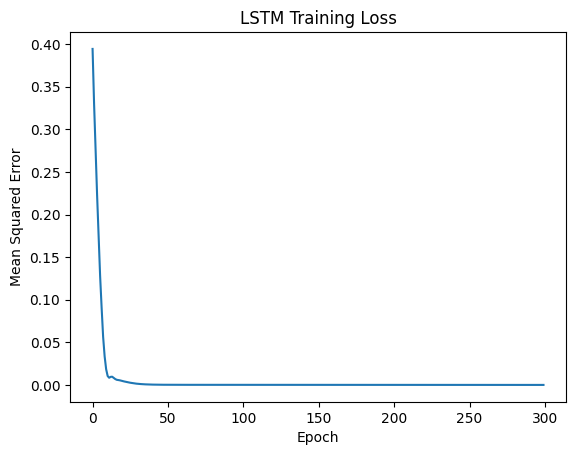

In [10]:
# ==========================================================
# STEP 8: VISUALIZE TRAINING LOSS
# ==========================================================

# Plot training loss
plt.plot(history.history["loss"])

# Add graph title
plt.title("LSTM Training Loss")

# Add axis labels
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")

# Display graph
plt.show()


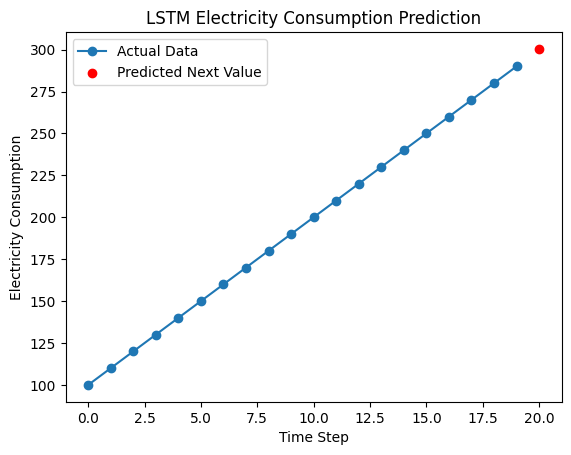

In [11]:
# ==========================================================
# STEP 9: VISUALIZE ACTUAL DATA AND PREDICTION
# ==========================================================

# Create time steps for original data
time_steps = np.arange(len(data))

# Plot original electricity values
plt.plot(
    time_steps,
    data,
    marker="o",
    label="Actual Data"
)

# Plot predicted next value
plt.scatter(
    len(data),
    prediction[0][0],
    color="red",
    label="Predicted Next Value"
)

# Add graph title
plt.title("LSTM Electricity Consumption Prediction")

# Add axis labels
plt.xlabel("Time Step")
plt.ylabel("Electricity Consumption")

# Display legend
plt.legend()

# Display graph
plt.show()